In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("soheiltehranipour/snappfood-persian-sentiment-analysis")

print("Path to dataset files:", path)

Dataset loaded successfully.

Dataset Shape: (70000, 4)

--- Column Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  520 non-null    object 
 1   comment     70000 non-null  object 
 2   label       70000 non-null  object 
 3   label_id    69480 non-null  float64
dtypes: float64(1), object(3)
memory usage: 2.1+ MB
None

--- First 5 Rows ---


,Unnamed: 0,comment,label,label_id
0,NaN,واقعا حیف وقت که بنویسم سرویس دهیتون شده افتضاح,SAD,1.0
1,NaN,قرار بود ۱ ساعته برسه ولی نیم ساعت زودتر از مو...,HAPPY,0.0
2,NaN,قیمت این مدل اصلا با کیفیتش سازگاری نداره، فقط...,SAD,1.0
3,NaN,عالللی بود همه چه درست و به اندازه و کیفیت خوب...,HAPPY,0.0
4,NaN,شیرینی وانیلی فقط یک مدل بود.,HAPPY,0.0



--- Class Distribution for 'label_id' ---
label_id
0.0    34916
1.0    34564
Name: count, dtype: int64


<local-path> FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=target_col, data=df, palette='viridis')


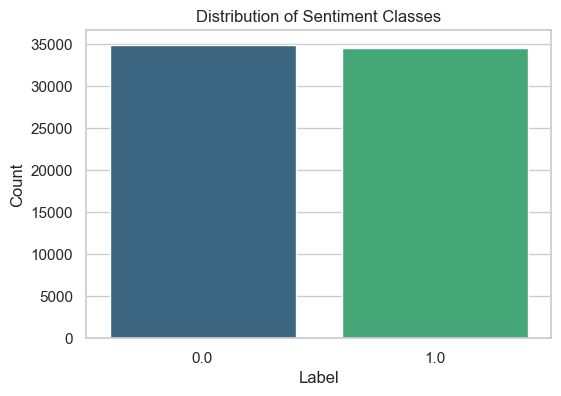


--- Text Length Statistics (Token Count) ---
count    70000.000000
mean        18.504029
std         15.807516
min          1.000000
25%          8.000000
50%         14.000000
75%         23.000000
max        361.000000
Name: token_count, dtype: float64


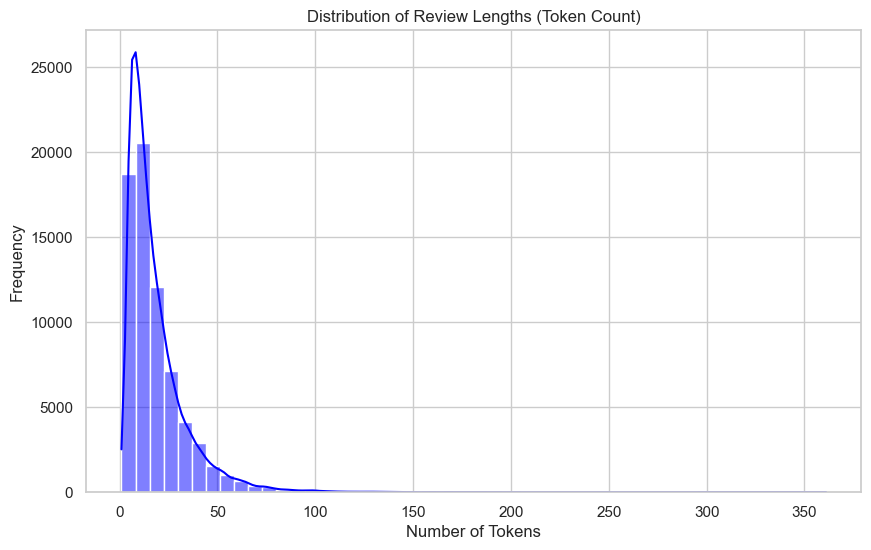

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set(style="whitegrid")

# ---------------------------------------------------------
# 1. Load the Dataset (Corrected with tab delimiter)
# ---------------------------------------------------------
try:
    # We use sep='\t' because the file is tab-separated
    df = pd.read_csv('Snappfood - Sentiment Analysis.csv', on_bad_lines='skip', sep='\t')
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print("Error: File not found. Please upload 'Snappfood - Sentiment Analysis.csv'")

# ---------------------------------------------------------
# 2. General Info & Structure
# ---------------------------------------------------------
print(f"\nDataset Shape: {df.shape}")
print("\n--- Column Info ---")
print(df.info())

print("\n--- First 5 Rows ---")
display(df.head()) # Displays the first 5 rows cleanly in Jupyter/Colab

# ---------------------------------------------------------
# 3. Class Distribution (Positive/Negative)
# ---------------------------------------------------------
# Identifying the label column
if 'label_id' in df.columns:
    target_col = 'label_id'
else:
    target_col = df.columns[-1]

print(f"\n--- Class Distribution for '{target_col}' ---")
print(df[target_col].value_counts())

# Plotting the Bar Chart
plt.figure(figsize=(6, 4))
sns.countplot(x=target_col, data=df, palette='viridis')
plt.title('Distribution of Sentiment Classes')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

# ---------------------------------------------------------
# 4. Text Length Analysis
# ---------------------------------------------------------
# Identifying the text column
if 'comment' in df.columns:
    text_col = 'comment'
else:
    text_col = df.columns[1]

# Calculate token count based on spaces
df['token_count'] = df[text_col].astype(str).apply(lambda x: len(x.split()))

print("\n--- Text Length Statistics (Token Count) ---")
print(df['token_count'].describe())

# Plotting the Length Distribution
plt.figure(figsize=(10, 6))
sns.histplot(df['token_count'], bins=50, kde=True, color='blue')
plt.title('Distribution of Review Lengths (Token Count)')
plt.xlabel('Number of Tokens')
plt.ylabel('Frequency')
plt.show()

In [15]:
%pip install hazm

In [18]:

import re
import pandas as pd
from hazm import Normalizer, word_tokenize, stopwords_list, Lemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

# ---------------------------------------------------------
# Step 1: Data Preparation
# ---------------------------------------------------------
# Drop rows where EITHER 'label_id' OR 'comment' is missing to prevent errors
df.dropna(subset=['label_id', 'comment'], inplace=True)

# Convert label_id to integer (0/1)
df['label_id'] = df['label_id'].astype(int)

# ---------------------------------------------------------
# Step 2: Advanced Preprocessing Function
# ---------------------------------------------------------
# Initialize tools
normalizer = Normalizer()
lemmatizer = Lemmatizer()
stop_words = set(stopwords_list())

def clean_text(text):
    if not isinstance(text, str):
        return ""
    
    # 1. Normalization (Standardize characters like 'ی' and 'ک')
    text = normalizer.normalize(text)
    
    # 2. Remove URLs
    text = re.sub(r'http\S+', '', text)
    
    # 3. Remove English characters
    text = re.sub(r'[a-zA-Z]', '', text)
    
    # 4. Remove Punctuation/Emojis (Keep only Persian characters)
    text = re.sub(r'[^\w\s\u0600-\u06FF]', ' ', text)
    
    # 5. Tokenization
    tokens = word_tokenize(text)
    
    # 6. Lemmatization & Stopword Removal
    cleaned_tokens = []
    for w in tokens:
        # Lemmatize (convert "می‌روم" -> "رفت")
        root = lemmatizer.lemmatize(w)
        
        # If lemmatizer returns "root#verb", take the first part
        if '#' in root:
            root = root.split('#')[0]
            
        # Check if the ROOT is a stopword or too short
        if root not in stop_words and len(root) > 1:
            cleaned_tokens.append(root)
    
    return " ".join(cleaned_tokens)

# Apply the cleaning function (This may take 2-3 minutes)
print("Preprocessing text with Lemmatization... please wait.")
df['clean_text'] = df['comment'].apply(clean_text)
print("Preprocessing complete!")

# Show comparison
print("\n--- Original vs Cleaned ---")
print(df[['comment', 'clean_text']].head())

# ---------------------------------------------------------
# Step 3: Train / Validation / Test Split (70% / 15% / 15%)
# ---------------------------------------------------------
# First Split: 70% Train, 30% Temp
X_train_text, X_temp, y_train, y_temp = train_test_split(
    df['clean_text'], df['label_id'], 
    test_size=0.30, 
    random_state=42, 
    stratify=df['label_id']
)

# Second Split: Divide the 30% Temp into equal halves (15% Val, 15% Test)
X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp, y_temp, 
    test_size=0.50, 
    random_state=42, 
    stratify=y_temp
)

print(f"\nTrain size: {len(X_train_text)}")
print(f"Val size:   {len(X_val_text)}")
print(f"Test size:  {len(X_test_text)}")

# ---------------------------------------------------------
# Step 4: Feature Extraction (Vectorization)
# ---------------------------------------------------------
# IMPORTANT: Fit vectorizers ONLY on Training data

# 1. Bag-of-Words (CountVectorizer)
count_vect = CountVectorizer(max_features=5000)
X_train_count = count_vect.fit_transform(X_train_text)
X_val_count = count_vect.transform(X_val_text)
X_test_count = count_vect.transform(X_test_text)

# 2. TF-IDF (TfidfVectorizer)
tfidf_vect = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf_vect.fit_transform(X_train_text)
X_val_tfidf = tfidf_vect.transform(X_val_text)
X_test_tfidf = tfidf_vect.transform(X_test_text)

print("\nVectorization complete.")
print(f"Count Vectors (Train): {X_train_count.shape}")
print(f"TF-IDF Vectors (Train): {X_train_tfidf.shape}")

Preprocessing text with Lemmatization... please wait.
Preprocessing complete!

--- Original vs Cleaned ---
                                             comment  \
0    واقعا حیف وقت که بنویسم سرویس دهیتون شده افتضاح   
1  قرار بود ۱ ساعته برسه ولی نیم ساعت زودتر از مو...   
2  قیمت این مدل اصلا با کیفیتش سازگاری نداره، فقط...   
3  عالللی بود همه چه درست و به اندازه و کیفیت خوب...   
4                      شیرینی وانیلی فقط یک مدل بود.   

                                          clean_text  
0             واقعا حیف وقت نوشت سرویس دهیتون افتضاح  
1  قرار ساعته برسه نیم ساعت زودتر موقع دید چقدر پ...  
2  قیمت مدل اصلا کیفیت سازگاری نداره ظاهر فریبنده...  
3  درست اندازه کیفیت امیداورم کیفیتتون باشه مشتری...  
4                                   شیرینی وانیل مدل  

Train size: 48636
Val size:   10422
Test size:  10422

Vectorization complete.
Count Vectors (Train): (48636, 5000)
TF-IDF Vectors (Train): (48636, 5000)


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import cross_validate
import pandas as pd

# ---------------------------------------------------------
# Step 1: Define Models
# ---------------------------------------------------------
# We increase max_iter to ensure the models have enough time to find the best solution
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Linear SVM": LinearSVC(dual="auto", max_iter=1000, random_state=42),
    "Naive Bayes": MultinomialNB()
}

# ---------------------------------------------------------
# Step 2: Define Evaluation Function (Cross-Validation)
# ---------------------------------------------------------
def evaluate_models(X, y, feature_name):
    results = []
    scoring = ['accuracy', 'f1_macro']
    
    print(f"\n--- Evaluating models on {feature_name} features ---")
    
    for name, model in models.items():
        # Perform 5-Fold Cross-Validation
        cv_results = cross_validate(model, X, y, cv=5, scoring=scoring)
        
        # Calculate averages
        avg_acc = cv_results['test_accuracy'].mean()
        avg_f1 = cv_results['test_f1_macro'].mean()
        
        print(f"{name}: Accuracy={avg_acc:.4f}, Macro F1={avg_f1:.4f}")
        
        results.append({
            "Feature Type": feature_name,
            "Model": name,
            "Accuracy": avg_acc,
            "Macro F1": avg_f1
        })
        
    return results

# ---------------------------------------------------------
# Step 3: Run Evaluation
# ---------------------------------------------------------
all_results = []

# 1. Evaluate on Bag-of-Words (Count)
results_count = evaluate_models(X_train_count, y_train, "Bag-of-Words")
all_results.extend(results_count)

# 2. Evaluate on TF-IDF
results_tfidf = evaluate_models(X_train_tfidf, y_train, "TF-IDF")
all_results.extend(results_tfidf)

# ---------------------------------------------------------
# Step 4: Comparison Table
# ---------------------------------------------------------
results_df = pd.DataFrame(all_results)
results_df = results_df.sort_values(by="Macro F1", ascending=False)

print("\n\n--- Final Comparison Table ---")
display(results_df)


--- Evaluating models on Bag-of-Words features ---
Logistic Regression: Accuracy=0.8113, Macro F1=0.8113
Linear SVM: Accuracy=0.7993, Macro F1=0.7993
Naive Bayes: Accuracy=0.8071, Macro F1=0.8066

--- Evaluating models on TF-IDF features ---
Logistic Regression: Accuracy=0.8182, Macro F1=0.8182
Linear SVM: Accuracy=0.8066, Macro F1=0.8066
Naive Bayes: Accuracy=0.8044, Macro F1=0.8038


--- Final Comparison Table ---


,Feature Type,Model,Accuracy,Macro F1
3,TF-IDF,Logistic Regression,0.818242,0.818156
0,Bag-of-Words,Logistic Regression,0.811333,0.811326
4,TF-IDF,Linear SVM,0.806645,0.806601
2,Bag-of-Words,Naive Bayes,0.807077,0.806588
5,TF-IDF,Naive Bayes,0.804445,0.803778
1,Bag-of-Words,Linear SVM,0.799346,0.799330


--- Tuning Hyperparameters on Validation Set ---
C=0.1: Validation Macro F1 = 0.8142
C=1: Validation Macro F1 = 0.8173
C=10: Validation Macro F1 = 0.8079
C=100: Validation Macro F1 = 0.7960

Best C selected: 1

--- Final Test Set Results ---
Accuracy: 0.8195
Macro F1: 0.8194

Classification Report:
               precision    recall  f1-score   support

   Happy (0)       0.84      0.79      0.81      5238
     Sad (1)       0.80      0.85      0.82      5184

    accuracy                           0.82     10422
   macro avg       0.82      0.82      0.82     10422
weighted avg       0.82      0.82      0.82     10422



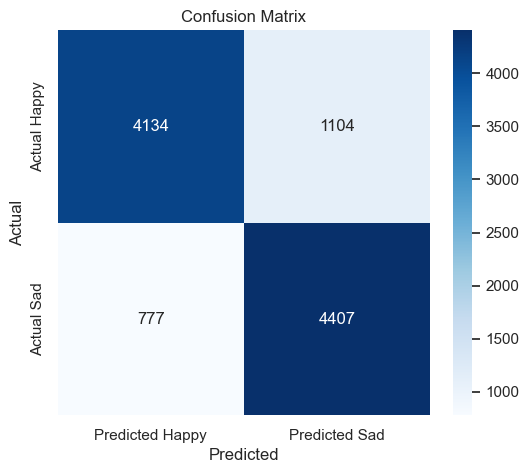


Total Errors: 1881
--- 5 Examples of Misclassification ---

Text: خوشمزه خصوصا اون کرم سفیدرنگ وسط
Actual: Sad | Predicted: Happy
--------------------------------------------------

Text: نون سبزیجات بیات
Actual: Happy | Predicted: Sad
--------------------------------------------------

Text: هفته رستوران خرید پیتزا مخلفات باشه مخلفات امد خوش برام اسنپ انتقال عذر خواهی_تمامش خوش آبند تر پیتزا دیگه خورد تعویض نکردن بایست عوض میکردن خودم رستوران زنحیره ایی اسنپ ثبت میتونن مشاهده کنن قانون برندینگ فرانچایز بلدم کار قبول لطیف
Actual: Sad | Predicted: Happy
--------------------------------------------------

Text: باتوجه توضیحات تآکید فلفل دلمه ای باشه سیب زمینی پیتزا فلفل دلمه ای پیتزا کف بسته بست چسبید
Actual: Sad | Predicted: Happy
--------------------------------------------------

Text: ایندفعه کوکا مشکی نوشابه زرد مختلف فرستاد موضوع نوشت براتون
Actual: Happy | Predicted: Sad
--------------------------------------------------


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ---------------------------------------------------------
# Step 1: Hyperparameter Tuning (Using Validation Set)
# ---------------------------------------------------------
# We try different "C" values. Smaller C = Stronger regularization (simpler model).
C_candidates = [0.1, 1, 10, 100]
best_f1 = 0
best_C = 1

print("--- Tuning Hyperparameters on Validation Set ---")
for C in C_candidates:
    model = LogisticRegression(C=C, max_iter=1000, random_state=42)
    model.fit(X_train_tfidf, y_train)
    
    # Evaluate on Validation
    val_preds = model.predict(X_val_tfidf)
    val_f1 = f1_score(y_val, val_preds, average='macro')
    
    print(f"C={C}: Validation Macro F1 = {val_f1:.4f}")
    
    if val_f1 > best_f1:
        best_f1 = val_f1
        best_C = C

print(f"\nBest C selected: {best_C}")

# ---------------------------------------------------------
# Step 2: Final Training & Testing
# ---------------------------------------------------------
# Train final model with Best C
final_model = LogisticRegression(C=best_C, max_iter=1000, random_state=42)
final_model.fit(X_train_tfidf, y_train)

# Predict on TEST set
test_preds = final_model.predict(X_test_tfidf)

# Report Metrics
test_acc = accuracy_score(y_test, test_preds)
test_f1 = f1_score(y_test, test_preds, average='macro')

print(f"\n--- Final Test Set Results ---")
print(f"Accuracy: {test_acc:.4f}")
print(f"Macro F1: {test_f1:.4f}")
print("\nClassification Report:\n", classification_report(y_test, test_preds, target_names=['Happy (0)', 'Sad (1)']))

# ---------------------------------------------------------
# Step 3: Confusion Matrix
# ---------------------------------------------------------
cm = confusion_matrix(y_test, test_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted Happy', 'Predicted Sad'], yticklabels=['Actual Happy', 'Actual Sad'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# ---------------------------------------------------------
# Step 4: Error Analysis (Find 5 Mistakes)
# ---------------------------------------------------------
# Create a DataFrame of Test data to easily find mistakes
test_df = pd.DataFrame({
    'text': X_test_text, # The text from our split
    'actual': y_test,
    'predicted': test_preds
})

# Filter for rows where Actual != Predicted
errors = test_df[test_df['actual'] != test_df['predicted']]

print(f"\nTotal Errors: {len(errors)}")
print("--- 5 Examples of Misclassification ---")

# Display 5 random errors
for i, row in errors.sample(5, random_state=42).iterrows():
    act_label = "Sad" if row['actual'] == 1 else "Happy"
    pred_label = "Sad" if row['predicted'] == 1 else "Happy"
    print(f"\nText: {row['text']}")
    print(f"Actual: {act_label} | Predicted: {pred_label}")
    print("-" * 50)